# Linear Regression

How much of the variation in strength can a straight-line model explain? Each ingredient gets one coefficient, with age entering as another additive term.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from gallery.tabular import concrete_split, regression_report

model = LinearRegression()

## Data and split

All ages of a concrete recipe stay in the same partition. Five training folds also keep recipes together. The final test uses unseen mixes.

In [3]:
X, X_test, y, y_test, groups = concrete_split()

## Held-out predictions

The table includes a training-only baseline. Both panels use the untouched test observations.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.580, MAE 8.35 MPa
                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.633      8.509      10.453            6.893                  -0.750
Training mean -0.002     14.236      17.267           13.145                  -0.829
cement              0.123
slag                0.108
fly_ash             0.089
water              -0.091
superplasticiser    0.436
coarse_aggregate    0.024
fine_aggregate      0.027
age                 0.109


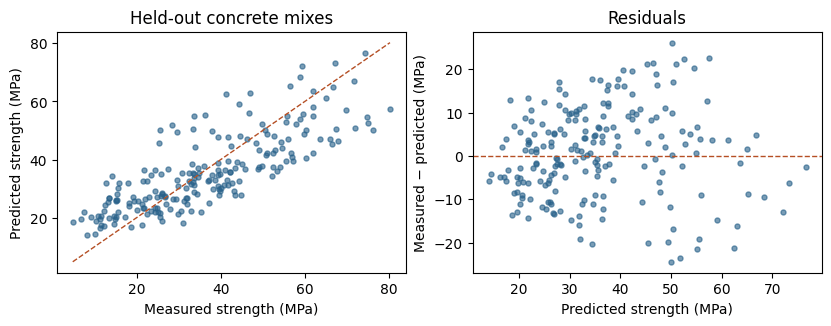

In [4]:
predictions = regression_report(model, X, X_test, y, y_test, groups)
import pandas as pd

print(pd.Series(model.coef_, index=X.columns, name="MPa per original unit").round(3).to_string())
plt.show()

## Reading the result

A curved residual pattern would suggest that a constant change per additional day misses part of the curing process.

## References

[scikit-learn, LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)